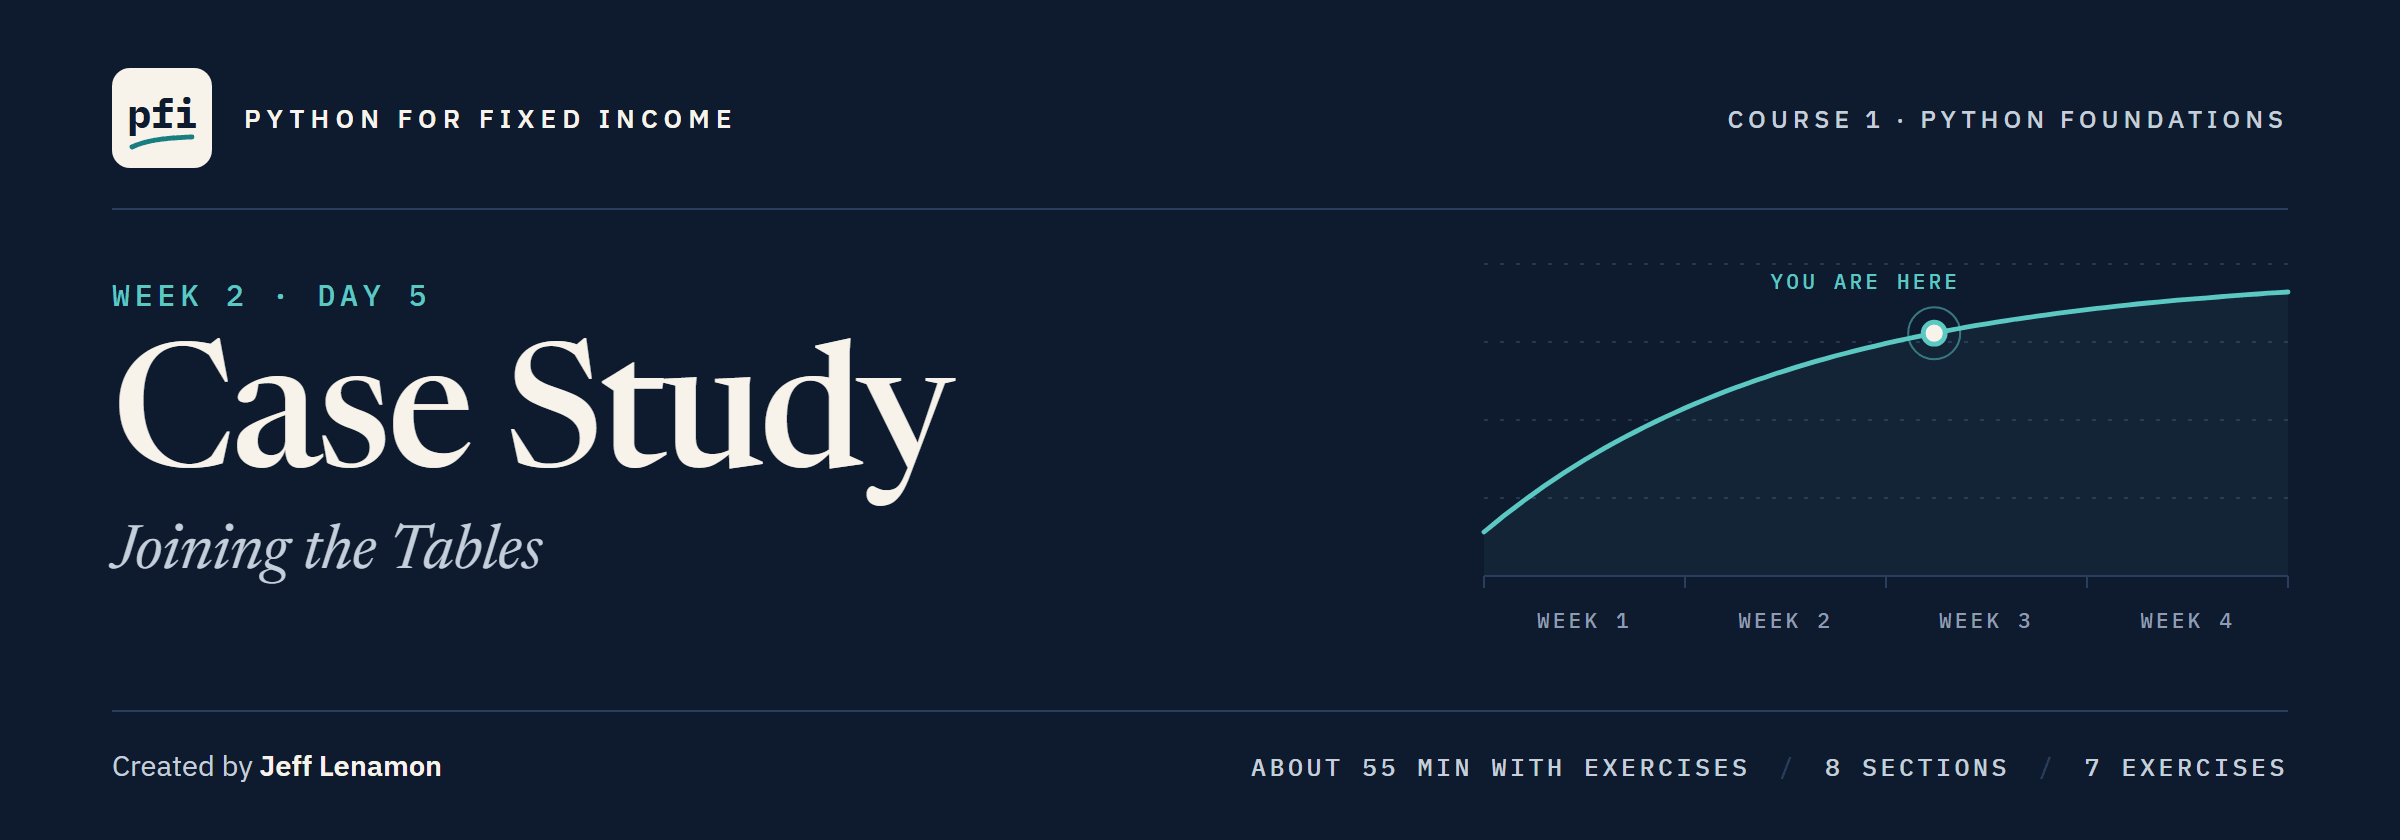

# Case Study: Joining the Tables

Week 2, Day 5. The three tables checked yesterday are joined into one book, and the desk's questions are answered from it.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week2/day5/10_case_study_joining_the_tables.ipynb)

## Problem Definition

### Context

The desk lead's fifteenth note:

> Yesterday's files passed every check. Join them into one book and hold it to your numbers: 200 rows, 13 columns, 489,000,000 of face. Give every bond a value at the clean price, its coupon income, and a weight. Then where does the money sit: by sector, by grade (by count and by value, and say which), by rating in credit order? What is our average rating, which the letters could not give you? Which ten issuers carry the most, and what share? What matures first, and who are yesterday's seven flagged bonds? Send one workbook, the book and the answers, and leave nothing behind.

### Objective

You are the desk's analyst.
Build one book, prove nothing was lost or doubled, then answer every question from that one table.

### The Data

Yesterday's findings, as of 2026-09-30; the issuers and CUSIPs are invented.

<table align="left">
<tr><th align="left">File</th><th align="left">One row is</th><th align="left">Rows, columns</th><th align="left">Joins on</th></tr>
<tr><td align="left"><code>positions.csv</code></td><td align="left">one bond held, 489,000,000 of face in all</td><td align="left">200, 6</td><td align="left"><code>ticker</code></td></tr>
<tr><td align="left"><code>issuers.csv</code></td><td align="left">one issuer, every ticker found</td><td align="left">150, 5</td><td align="left"><code>ticker</code>, then <code>rating</code></td></tr>
<tr><td align="left"><code>ratings.csv</code></td><td align="left">one rating, every rating found</td><td align="left">18, 4</td><td align="left"><code>rating</code></td></tr>
</table>
<br clear="left">

Prices are clean, per 100 of face; coupons are annual percentages of face.
`maturity` arrives as text.

### How We Will Work

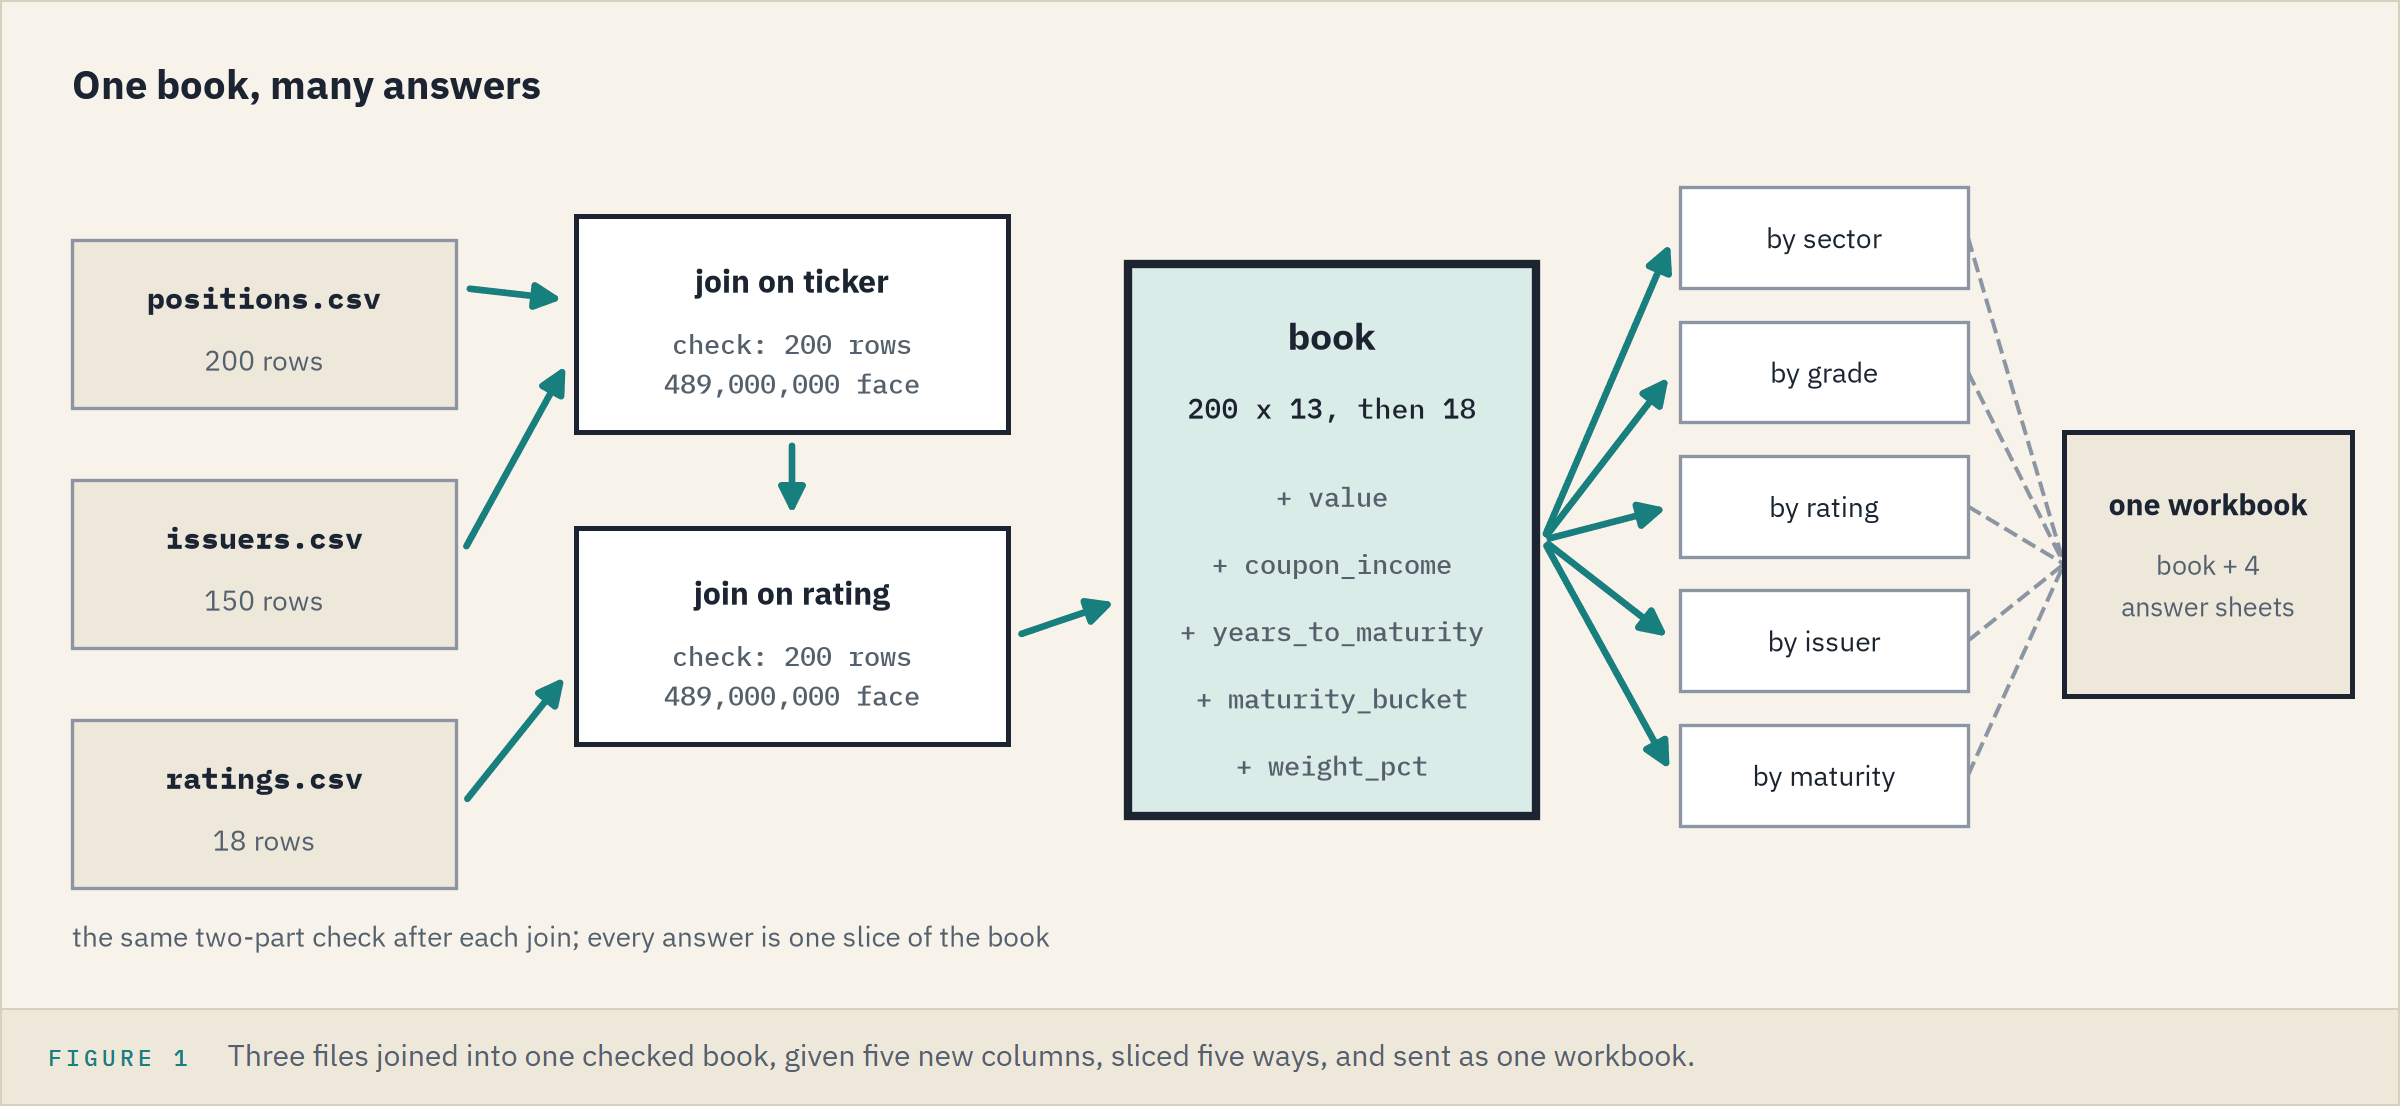

**One book, then one line per question.**

## Your Route Through Day 5

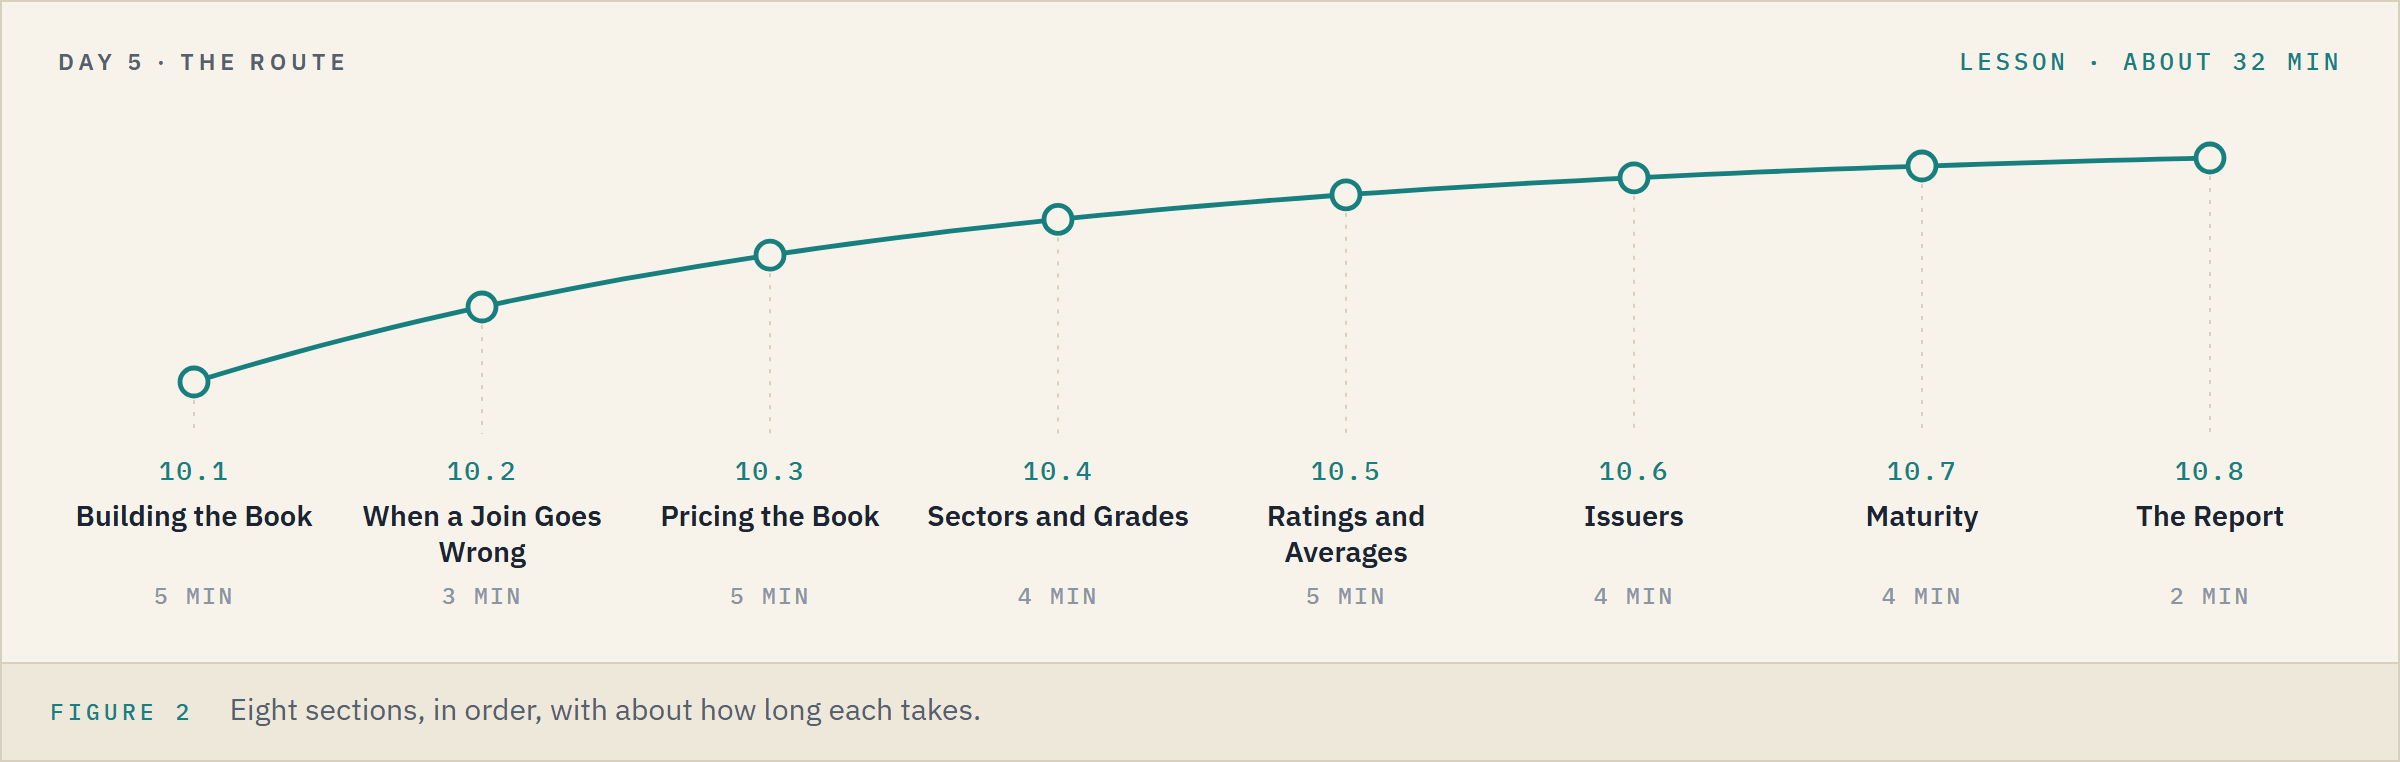

**Time.** About 32 minutes for the lesson, then about 21 for the seven exercises.

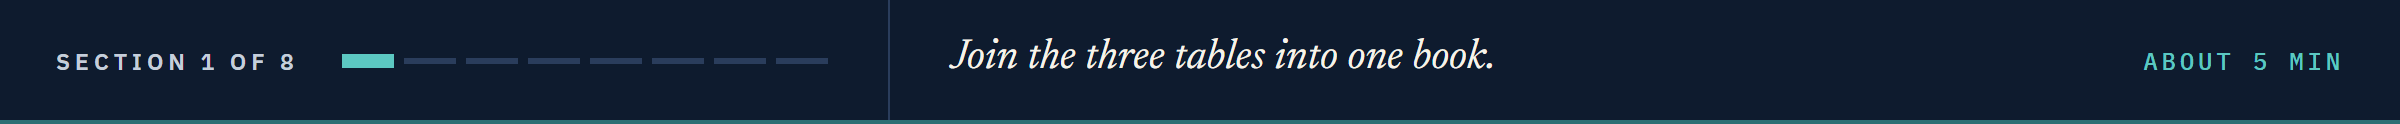

## 10.1 Building the Book

### Three Files, Two Numbers

Q. Load the three files, and store the two numbers every join must keep.

In [1]:
import os

import pandas as pd

# the repo's data folder on your machine; in Colab, GitHub, as yesterday
if os.path.exists('../../../data/positions.csv'):
    data_folder = '../../../data/'
else:
    data_folder = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/'
positions = pd.read_csv(data_folder + 'positions.csv')
issuers = pd.read_csv(data_folder + 'issuers.csv')
ratings = pd.read_csv(data_folder + 'ratings.csv')

In [2]:
# yesterday's numbers, stored under names: the checks compare names, not memories
rows_before = positions.shape[0]
face_before = positions['par_held'].sum()
print(rows_before, face_before)

200 489000000


### Positions to Issuers

Q. Join the issuers onto the positions, then check both numbers.

In [3]:
# a left join keeps every position; validate= refuses a repeated ticker, as in Combining Part 1
step_one = pd.merge(positions, issuers, on='ticker', how='left', validate='many_to_one')
# week 1's Day 3 assert: silent when true
assert step_one.shape[0] == rows_before, 'the join changed the row count'
assert step_one['par_held'].sum() == face_before, 'the join changed the face'
print(step_one.shape)

(200, 10)


Ten columns, as yesterday's Predict 5 wrote down; both `assert` lines were silent.
`==` is exact, right for a count and for whole dollars; decimals will need NumPy Part 1's `np.isclose()`.

**Rows and face unchanged: the first join is safe.**

### Every Position Found

Q. Did every position find its issuer? Show the first rows.

In [4]:
# a gap in a column the join brought in would mean a ticker found nothing
print(step_one[['issuer', 'sector', 'rating']].isna().sum())
step_one.head(4)

issuer    0
sector    0
rating    0
dtype: int64


,cusip,ticker,coupon,maturity,price,par_held,issuer,sector,country,rating
0,99080CAE8,BEZE,7.000,2032-06-18,106.727,5000000,Bezane Finance,Financials,US,BBB-
1,99049XAE2,BEZH,8.125,2029-04-17,97.556,250000,Bezamyth Machinery,Industrials,US,B
2,99039NAC0,BEZL,5.125,2030-06-03,98.730,1500000,Bezoquil Freight,Transportation,US,BB
3,99039NAG1,BEZL,6.125,2053-04-09,92.261,500000,Bezoquil Freight,Transportation,US,BB


No gaps.
BEZE reads Bezane Finance, Financials, BBB-; both BEZL bonds carry one issuer row: many to one.

### The Grade? Not Yet

Q. Add up the face in each grade.

In [5]:
# the face by grade, from the first join
step_one.groupby('grade')['par_held'].sum()

KeyError: 'grade'

Read the last line, as on week 1's Day 3: there is no column called `grade` yet.

**The grade is in the third table.**

### Then to the Rating Scale

Q. Join the scale on `rating`, run the same check, and look at one row.

In [6]:
# the second join, the same guard and the same two asserts
book = pd.merge(step_one, ratings, on='rating', how='left', validate='many_to_one')
assert book.shape[0] == rows_before, 'the join changed the row count'
assert book['par_held'].sum() == face_before, 'the join changed the face'
# gaps in the three new columns, added into one number, as yesterday
print(book.shape, book[['score', 'bucket', 'grade']].isna().sum().sum())
# one row, shown down the page
book.iloc[0]

(200, 13) 0


cusip              99080CAE8
ticker                  BEZE
coupon                   7.0
maturity          2032-06-18
price                106.727
par_held             5000000
issuer        Bezane Finance
sector            Financials
country                   US
rating                  BBB-
score                     10
bucket                   BBB
grade       Investment Grade
Name: 0, dtype: object

One row is still one bond held, now carrying its issuer and its grade.

### The Grade Split Ties

Q. Now add up the face in each grade.

In [7]:
# the cell that failed now runs
book.groupby('grade')['par_held'].sum()

grade
High Yield          169250000
Investment Grade    319750000
Name: par_held, dtype: int64

169,250,000 plus 319,750,000 is 489,000,000.

**200 rows, 13 columns, 489,000,000: yesterday's numbers hold.**

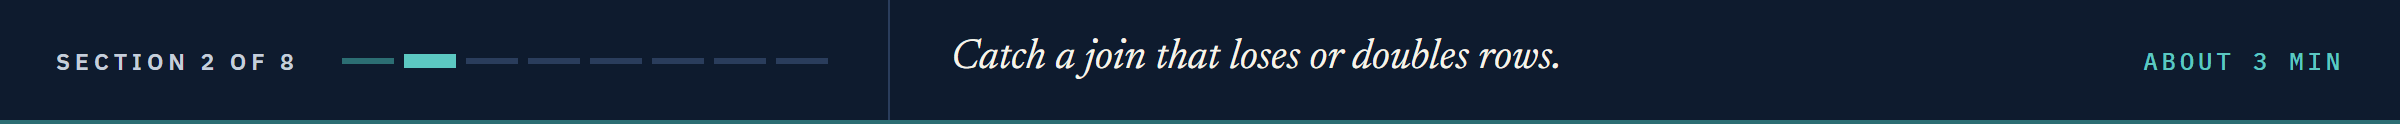

## 10.2 When a Join Goes Wrong

### Keep Everything

Q. What if the join kept every issuer too? Run an outer join, count where each row was found, and show one issuer with no bond.

In [8]:
# how='outer' and indicator=, as in Combining Part 1
everything = pd.merge(positions, issuers, on='ticker', how='outer', indicator=True)
print(everything.shape)
print(everything['_merge'].value_counts())
everything[everything['_merge'] == 'right_only'].head(1)

(235, 11)
_merge
both          200
right_only     35
left_only       0
Name: count, dtype: int64


,cusip,ticker,coupon,maturity,price,par_held,issuer,sector,country,rating,_merge
7,NaN,BEZY,NaN,NaN,NaN,NaN,Bezolvey Chemicals,Materials,US,BBB,right_only


The 35 `right_only` rows are yesterday's issuers with no bond: `NaN` where the bond should be.

### The Face of the Outer Join

**Predict 1**

Q. `everything` has 235 rows, 35 of them with no face. What does `everything['par_held'].sum()` give?

A) 489,000,000, the positions' face.
B) More than 489,000,000.
C) `NaN`: the blanks spoil the total.

In [9]:
# the face check on its own
print(everything['par_held'].sum())

489000000.0


A: `sum()` skips `NaN`, so the face check passes; the `.0` appears because a column holding `NaN` is stored as decimals.
Only the row count catches this join, which is why the check has two parts.

### The Row Check Stops It

Q. Run the row check, with both numbers in the message.

In [10]:
# an f-string message says what was expected and what was found
rows_after = everything.shape[0]
assert rows_after == rows_before, f'expected {rows_before} rows, found {rows_after}'

AssertionError: expected 200 rows, found 235

### Every Way to Write It

<table align="left">
<tr><th align="left">The join written as</th><th align="left">Rows</th><th align="left">Face</th><th align="left">Caught by</th></tr>
<tr><td align="left"><code>how='left'</code>, <code>validate='many_to_one'</code></td><td align="left">200</td><td align="left">489,000,000</td><td align="left">passes both checks</td></tr>
<tr><td align="left"><code>how='outer'</code></td><td align="left">235</td><td align="left">489,000,000</td><td align="left">the row check only</td></tr>
<tr><td align="left"><code>how='inner'</code></td><td align="left">200 here</td><td align="left">489,000,000 here</td><td align="left">both checks, the month a ticker goes missing</td></tr>
<tr><td align="left">a ticker listed twice in <code>issuers</code></td><td align="left">more</td><td align="left">more</td><td align="left"><code>validate=</code> refuses it before either check</td></tr>
</table>
<br clear="left">

**Excel side by side.** A lookup column in G:

<table align="left">
<tr><th align="left">Job</th><th align="left">pandas</th><th align="left">Excel</th></tr>
<tr><td align="left">A ticker not found</td><td align="left"><code>NaN</code>, counted with <code>isna().sum()</code></td><td align="left"><code>#N/A</code>, counted with <code>=SUMPRODUCT(--ISNA(G2:G201))</code></td></tr>
<tr><td align="left">A ticker listed twice</td><td align="left">rows repeated; <code>validate=</code> refuses</td><td align="left"><code>VLOOKUP</code>, and <code>XLOOKUP</code> in Excel 2021 and Microsoft 365, take the first match, silently</td></tr>
</table>
<br clear="left">

**Left join, then both checks: rows and face.**

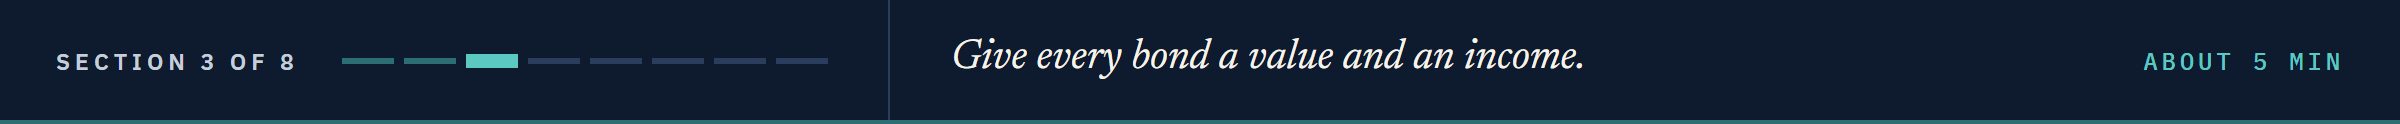

## 10.3 Pricing the Book

### Value at the Clean Price

Q. Value each bond: face times the clean price, over 100.

In [11]:
# the price is per 100 of face
book['value'] = book['par_held'] * book['price'] / 100
book[['ticker', 'par_held', 'price', 'value']].head(3)

,ticker,par_held,price,value
0,BEZE,5000000,106.727,5336350.0
1,BEZH,250000,97.556,243890.0
2,BEZL,1500000,98.730,1480950.0


BEZE's 5,000,000 at 106.727 is 5,336,350.
Clean means before accrued interest, so this is not a full market value; Exercise 4 adds the accrued.

### The Book's Value Against Its Face

**Predict 2**

Q. The simple average price is 98.83, under par. The next cell adds up `value`. Against the 489,000,000 of face, the total is:

A) Above it.
B) Below it.
C) Equal: premiums and discounts cancel.

In [12]:
total_value = book['value'].sum()
print('Value:', total_value)
# value per 100 of face: the average price, weighted by face
print('Per 100 of face:', round(total_value / face_before * 100, 3))

Value: 483024230.0
Per 100 of face: 98.778


B, by 5,975,770.
Weighted by face the price is 98.778, under the simple 98.83: averages hint, the sum settles it.

**483,024,230 at the clean price, on 489,000,000 of face.**

### Coupon Income

Q. What does each bond pay in a year, and the whole book?

In [13]:
# the coupon is paid on face, not on value
book['coupon_income'] = book['par_held'] * book['coupon'] / 100
print(book['coupon_income'].iloc[0], book['coupon_income'].sum())

350000.0 28864375.0


BEZE's 7 percent on 5,000,000 is 350,000 a year; the book earns 28,864,375.

### Years and Buckets

Q. Turn the maturity text into dates, in the book this time, then add the years to maturity and the four buckets.

In [14]:
# Combining Part 2's steps: dates, days over 365.25, then pd.cut() into four ranges
book['maturity'] = pd.to_datetime(book['maturity'])
as_of = pd.Timestamp('2026-09-30')
book['years_to_maturity'] = (book['maturity'] - as_of).dt.days / 365.25
book['maturity_bucket'] = pd.cut(book['years_to_maturity'], bins=[0, 3, 7, 15, 100],
                                 labels=['0 to 3', '3 to 7', '7 to 15', '15 and over'])
book['maturity_bucket'].value_counts().sort_index()

maturity_bucket
0 to 3         28
3 to 7         51
7 to 15        88
15 and over    33
Name: count, dtype: int64

The same 28, 51, 88, and 33 as Combining Part 2; yesterday the dates sat on the side, today the book keeps them.

### Weight

Q. Give each bond a weight: its share of the book's value, in percent. Which three weigh most?

In [15]:
book['weight_pct'] = book['value'] / total_value * 100
book.nlargest(3, 'weight_pct')[['ticker', 'par_held', 'price', 'weight_pct']]

,ticker,par_held,price,weight_pct
0,BEZE,5000000,106.727,1.104779
59,FESA,5000000,106.471,1.102129
104,LORX,5000000,104.801,1.084842


Three 5,000,000 positions above par: weight follows value, not face.
Combining Part 2 weighted by `market_value`, which holds accrued interest; these weights are on clean value.

Q. Do the weights add to 100?

In [16]:
import numpy as np

# a sum of 200 decimals can miss by a hair, so np.isclose(), not ==
assert np.isclose(book['weight_pct'].sum(), 100), 'the weights do not add to 100'
print(book['weight_pct'].sum(), book.shape)

100.0 (200, 18)


A total of 99.99999999999999 would be week 1's Day 3 float error, and would pass too.

**Excel side by side.** Coupon in C, maturity in D, price in E, face in F, value in N:

<table align="left">
<tr><th align="left">Column</th><th align="left">pandas</th><th align="left">Excel, filled down</th></tr>
<tr><td align="left"><code>value</code></td><td align="left"><code>book['par_held'] * book['price'] / 100</code></td><td align="left"><code>=F2 * E2 / 100</code></td></tr>
<tr><td align="left"><code>coupon_income</code></td><td align="left"><code>book['par_held'] * book['coupon'] / 100</code></td><td align="left"><code>=F2 * C2 / 100</code></td></tr>
<tr><td align="left"><code>years_to_maturity</code></td><td align="left"><code>(book['maturity'] - as_of).dt.days / 365.25</code></td><td align="left"><code>=(D2 - DATE(2026, 9, 30)) / 365.25</code></td></tr>
<tr><td align="left"><code>weight_pct</code></td><td align="left"><code>book['value'] / total_value * 100</code></td><td align="left"><code>=N2 / SUM($N$2:$N$201) * 100</code>, the anchors keep the total fixed</td></tr>
</table>
<br clear="left">

**Every bond has a value, an income, and a weight that add up: 200 rows, 18 columns.**

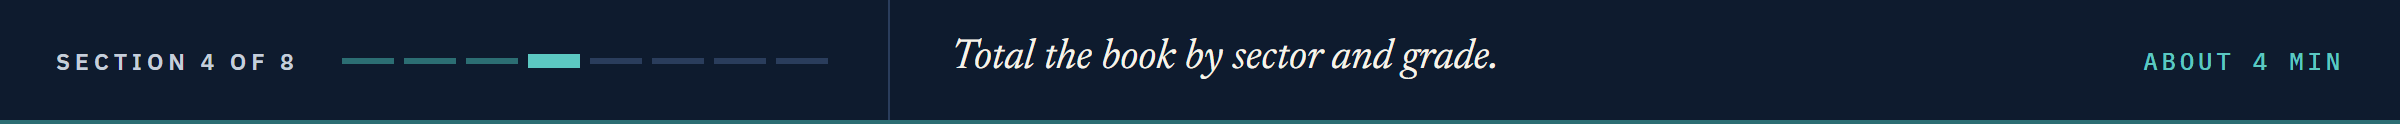

## 10.4 Sectors and Grades

From here every answer describes the data; none is a view on a bond or a sector.

### Value by Sector

Q. How many bonds and how much value sit in each sector, and what share of the book?

In [17]:
# named agg, as in Combining Part 1: one row per sector
by_sector = book.groupby('sector').agg(bonds=('cusip', 'count'), value=('value', 'sum'))
by_sector['share_pct'] = by_sector['value'] / total_value * 100
by_sector = by_sector.sort_values('value', ascending=False)
# the parts add back to the whole
assert by_sector['bonds'].sum() == rows_before, 'a bond is missing from the sectors'
assert np.isclose(by_sector['value'].sum(), total_value), 'value is missing from the sectors'
by_sector.round(2)

,bonds,value,share_pct
sector,,,
Materials,26,70527440.0,14.60
Financials,26,67067357.5,13.88
Consumer,26,55773490.0,11.55
Telecom,21,54953580.0,11.38
Industrials,20,51658930.0,10.69
Transportation,20,48159510.0,9.97
Health Care,20,38268482.5,7.92
Energy,17,38258305.0,7.92
Technology,12,29826430.0,6.17


Q. Draw all ten.

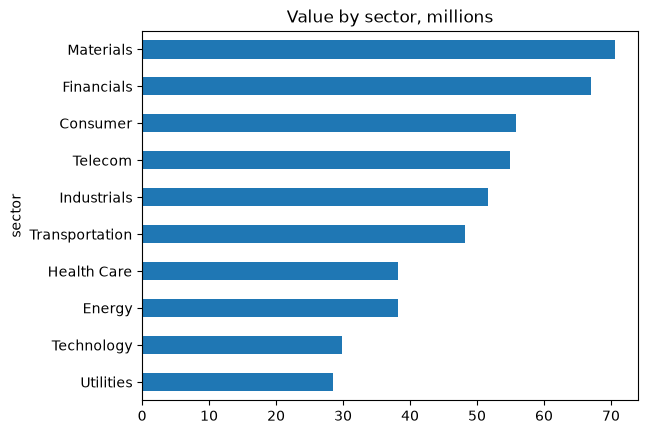

In [18]:
# plot.barh() lays the bars across, one row per label;
# sorted small to large, the largest lands on top
in_millions = by_sector['value'].sort_values() / 1000000
chart = in_millions.plot.barh(title='Value by sector, millions')

Materials leads at 14.60 percent and Utilities trails at 5.91; the top three each hold 26 bonds.

**Excel side by side.** A PivotTable with sector in Rows and Sum of value in Values; a second Sum of value, set to Show Values As, % of Grand Total, gives `share_pct`.

**Ten sectors add back to 200 bonds and 483,024,230.**

### By Count or by Value

Q. Split the book by grade. What share does each hold, by count and by value?

                  by count  by value
grade                               
High Yield            36.0     34.45
Investment Grade      64.0     65.55


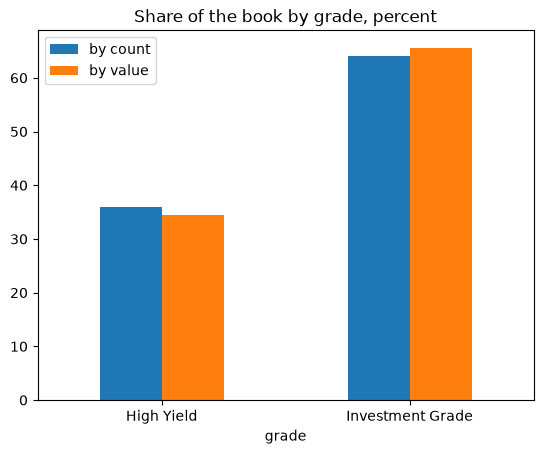

In [19]:
by_grade = book.groupby('grade').agg(bonds=('cusip', 'count'), value=('value', 'sum'))
# each share over its own total
shares = pd.DataFrame({'by count': by_grade['bonds'] / rows_before * 100,
                       'by value': by_grade['value'] / total_value * 100})
print(shares.round(2))
chart = shares.plot.bar(rot=0, title='Share of the book by grade, percent')

Investment grade is 64.0 percent of the bonds and 65.55 percent of the value: say which a share is of.

**Excel side by side.** Grade in M, value in N: `=COUNTIF(M:M, "High Yield")` counts, `=SUMIF(M:M, "High Yield", N:N)` adds the value.

### Below Par in Each Grade

Q. What share of each grade's bonds is priced below 100?

In [20]:
# a count per grade over a count per grade: pandas lines the two up by label
below_par = book[book['price'] < 100].groupby('grade')['cusip'].count()
print(below_par)
(below_par / by_grade['bonds'] * 100).round(1)

grade
High Yield          42
Investment Grade    71
Name: cusip, dtype: int64


grade
High Yield          58.3
Investment Grade    55.5
dtype: float64

71 of the 128 investment grade bonds and 42 of the 72 high yield: each count met its own grade's, matched by label as in pandas Part 1.
Below par compares a price with 100; it judges no bond.

### Each Sector Split by Grade

Q. Split each sector's value by grade, and draw it.

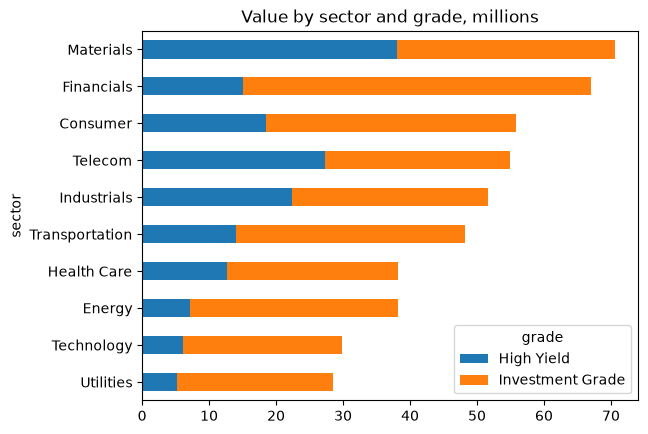

In [21]:
# Combining Part 2's grid, on value this time
sector_grade = pd.pivot_table(book, index='sector', columns='grade', values='value', aggfunc='sum')
# the chart's sector order is in_millions.index, the row labels (pandas Part 1); .loc[] applies it
sector_grade = sector_grade.loc[in_millions.index] / 1000000
# stacked=True piles a sector's two bars end to end
chart = sector_grade.plot.barh(stacked=True, title='Value by sector and grade, millions')

Materials is the one sector where the high yield part of the bar is longer than the investment grade part, as Combining Part 2 found on market value; Telecom is near even.
In Excel: Insert, Bar, Stacked Bar on the grid.

**Every share says what it was divided by.**

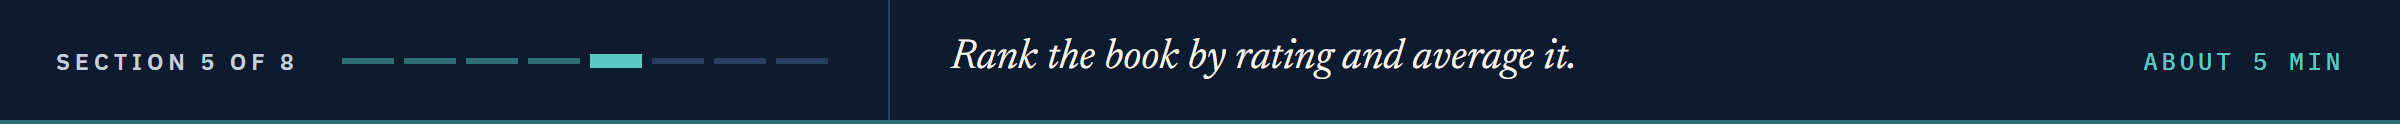

## 10.5 Ratings and Averages

### Credit Order From the Score

Q. Show the value in each rating bucket, AAA first, without typing the order.

In [22]:
# each bucket carries its best score, and sorting on that number gives credit order
by_bucket = book.groupby('bucket').agg(first_score=('score', 'min'), bonds=('cusip', 'count'),
                                       value=('value', 'sum'))
by_bucket = by_bucket.sort_values('first_score')
by_bucket['share_pct'] = (by_bucket['value'] / total_value * 100).round(2)
by_bucket

,first_score,bonds,value,share_pct
bucket,,,,
AAA,1,2,8102725.0,1.68
AA,2,8,12928850.0,2.68
A,5,56,146730275.0,30.38
BBB,8,62,148864277.5,30.82
BB,11,49,111511485.0,23.09
B,14,18,42653482.5,8.83
CCC,17,5,12233135.0,2.53


`groupby` sorts text, so A would come before AA; Combining Part 1 typed `credit_order` by hand.
This order comes from the scale itself, so next year's file needs no new list.

Q. Draw it, investment grade in green.

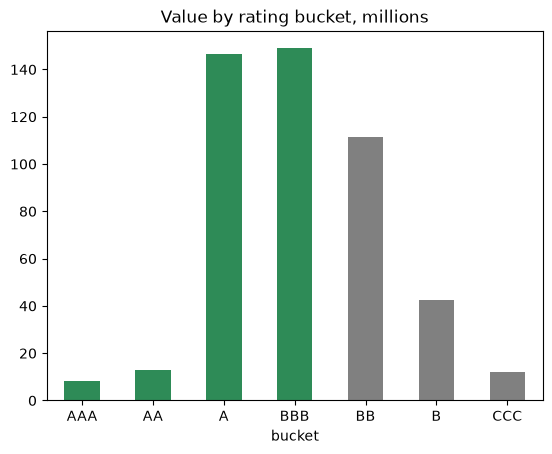

In [23]:
# one colour per bar, as on week 1's Day 5: green down to score 10, BBB-, then grey
colours = ['seagreen' if score <= 10 else 'grey' for score in by_bucket['first_score']]
chart = (by_bucket['value'] / 1000000).plot.bar(rot=0, color=colours,
                                                title='Value by rating bucket, millions')

BBB and A hold 30.82 and 30.38 percent; the three grey bars add to 34.45, the high yield share.

### The Average Rating

Q. Yesterday the letters had no mean. What are the book's average score and coupon, simple and weighted by value?

In [24]:
# Combining Part 2's weighted average: each number times its value, over the total value
weighted_score = (book['score'] * book['value']).sum() / total_value
weighted_coupon = (book['coupon'] * book['value']).sum() / total_value
print('Score, simple:', round(book['score'].mean(), 2), 'weighted:', round(weighted_score, 2))
print('Coupon, simple:', book['coupon'].mean(), 'weighted:', round(weighted_coupon, 4))

Score, simple: 9.36 weighted: 9.25
Coupon, simple: 5.9375 weighted: 5.9403


9.25 sits between BBB, score 9, and BBB-, score 10: the average rating yesterday's `TypeError` refused.
It treats every notch as one equal step, a convention, not a fact.

### A Shortcut With `weight_pct`

**Predict 3**

Q. `weight_pct` already holds each bond's share of the value. What does the next cell print? Write down a number.

In [25]:
# each coupon times its weight, added up
print(round((book['coupon'] * book['weight_pct']).sum(), 2))

594.03


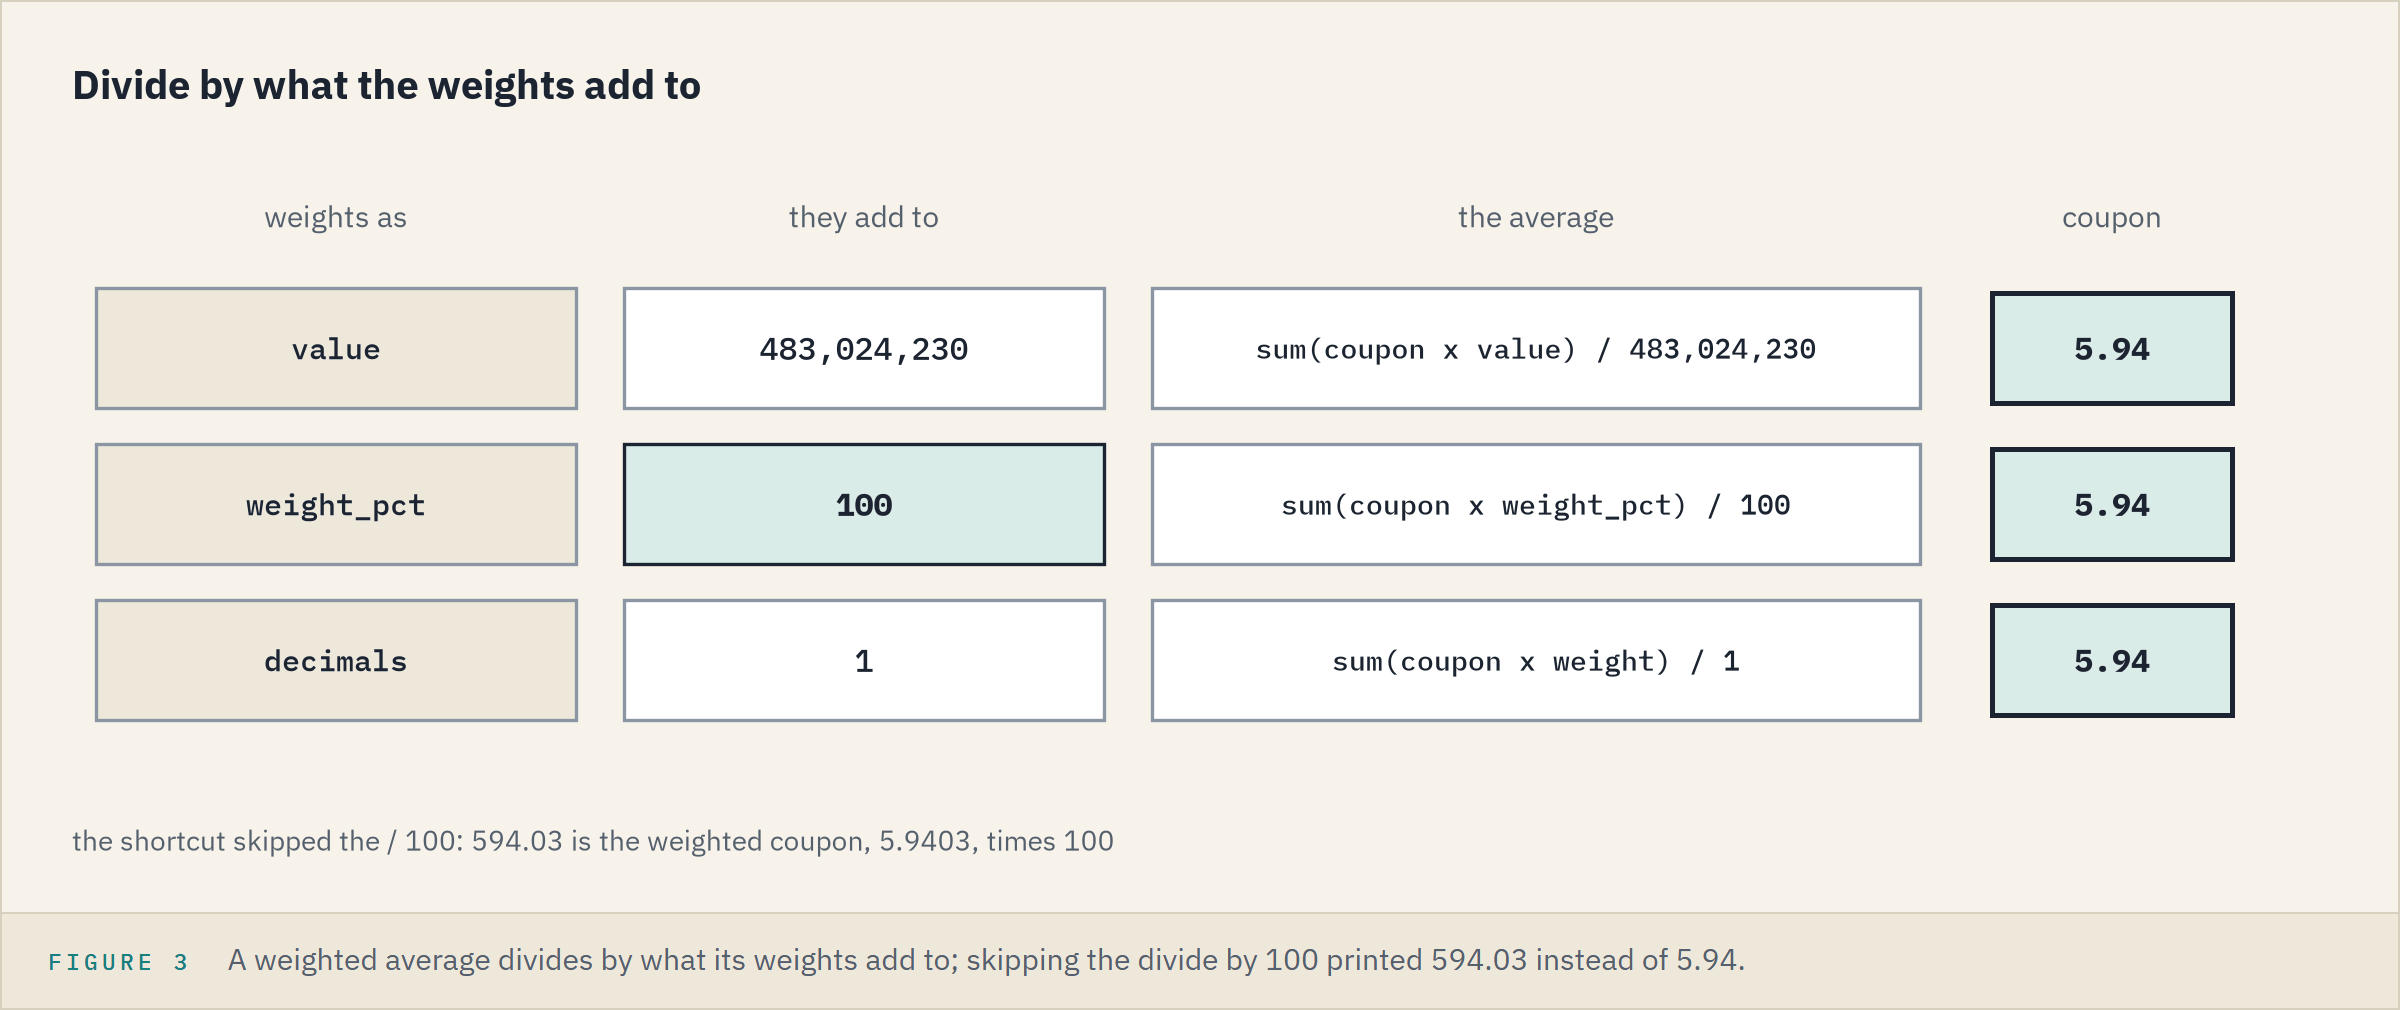

594.03 is 100 times the answer: the weights add to 100, not to 1.

**An average divides by what its weights add to.**

### Coupon by Grade

Q. What is the weighted coupon of each grade?

In [26]:
# Combining Part 2's two steps: the product as a column, then both summed in each grade
book['coupon_x_value'] = book['coupon'] * book['value']
sums = book.groupby('grade')[['coupon_x_value', 'value']].sum()
# the helper column has done its job: drop it, so the book keeps its 18 columns
book = book.drop(columns='coupon_x_value')
(sums['coupon_x_value'] / sums['value']).round(4)

grade
High Yield          7.3086
Investment Grade    5.2212
dtype: float64

Within a grade the divisor is that grade's value, not the book's.

**Excel side by side.** One grade, with coupon in C, grade in M, value in N: `=SUMPRODUCT((M2:M201="High Yield") * C2:C201 * N2:N201) / SUMIF(M2:M201, "High Yield", N2:N201)`.

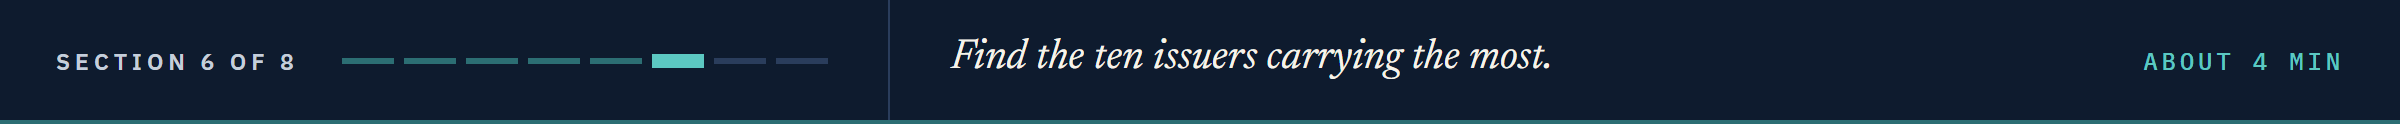

## 10.6 Issuers

### The Ten Largest Issuers

**Predict 4**

Q. 115 issuers stand behind the 200 bonds. What share of the book's value do the ten largest hold?

A) Under 10 percent: ten is under a tenth of 115.
B) About 20 percent.
C) Over 40 percent.

115 99834860.0 20.67


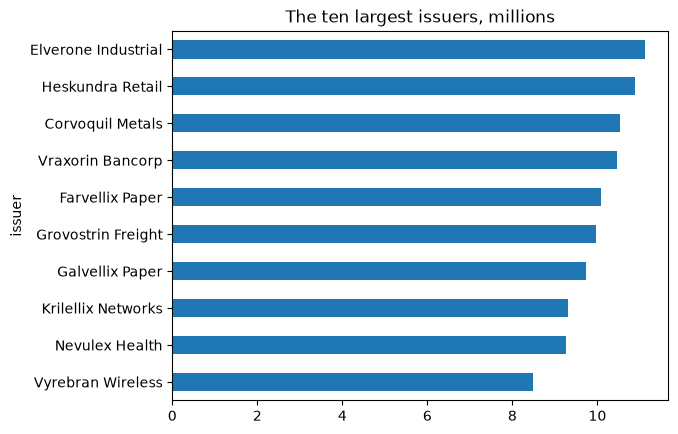

In [27]:
# group on the issuer name the join brought in: one row per issuer, not per bond
by_issuer = book.groupby('issuer')['value'].sum()
top_ten = by_issuer.nlargest(10)
print(len(by_issuer), top_ten.sum(), round(top_ten.sum() / total_value * 100, 2))
chart = (top_ten / 1000000).sort_values().plot.barh(title='The ten largest issuers, millions')

B: 99,834,860, 20.67 percent.
Elverone Industrial's bar is longest, 11.1 million, about twice BEZE's 5.3 million, the largest single bond; Nevulex Health, yesterday's six-bond NEVX, is ninth.

### Two Summaries, One Table

Q. For issuers with three bonds or more, put the bond count beside the average coupon.

In [28]:
# [['coupon']], a list of one name, keeps a table;
# reset_index() turns the issuer label into a column
avg_coupon = book.groupby('issuer')[['coupon']].mean().reset_index()
bond_count = book.groupby('issuer')[['cusip']].count().reset_index()
bond_count = bond_count.rename(columns={'cusip': 'bonds'})

In [29]:
# .merge() is pd.merge() written on the left table
several = bond_count[bond_count['bonds'] >= 3]
issuer_view = several.merge(avg_coupon, on='issuer', how='left')
print(issuer_view.shape)
issuer_view.sort_values('coupon', ascending=False).head(3)

(19, 3)


,issuer,bonds,coupon
7,Galvellix Paper,3,7.583333
11,Krilellix Networks,3,6.416667
8,Grovostrin Freight,3,6.375000


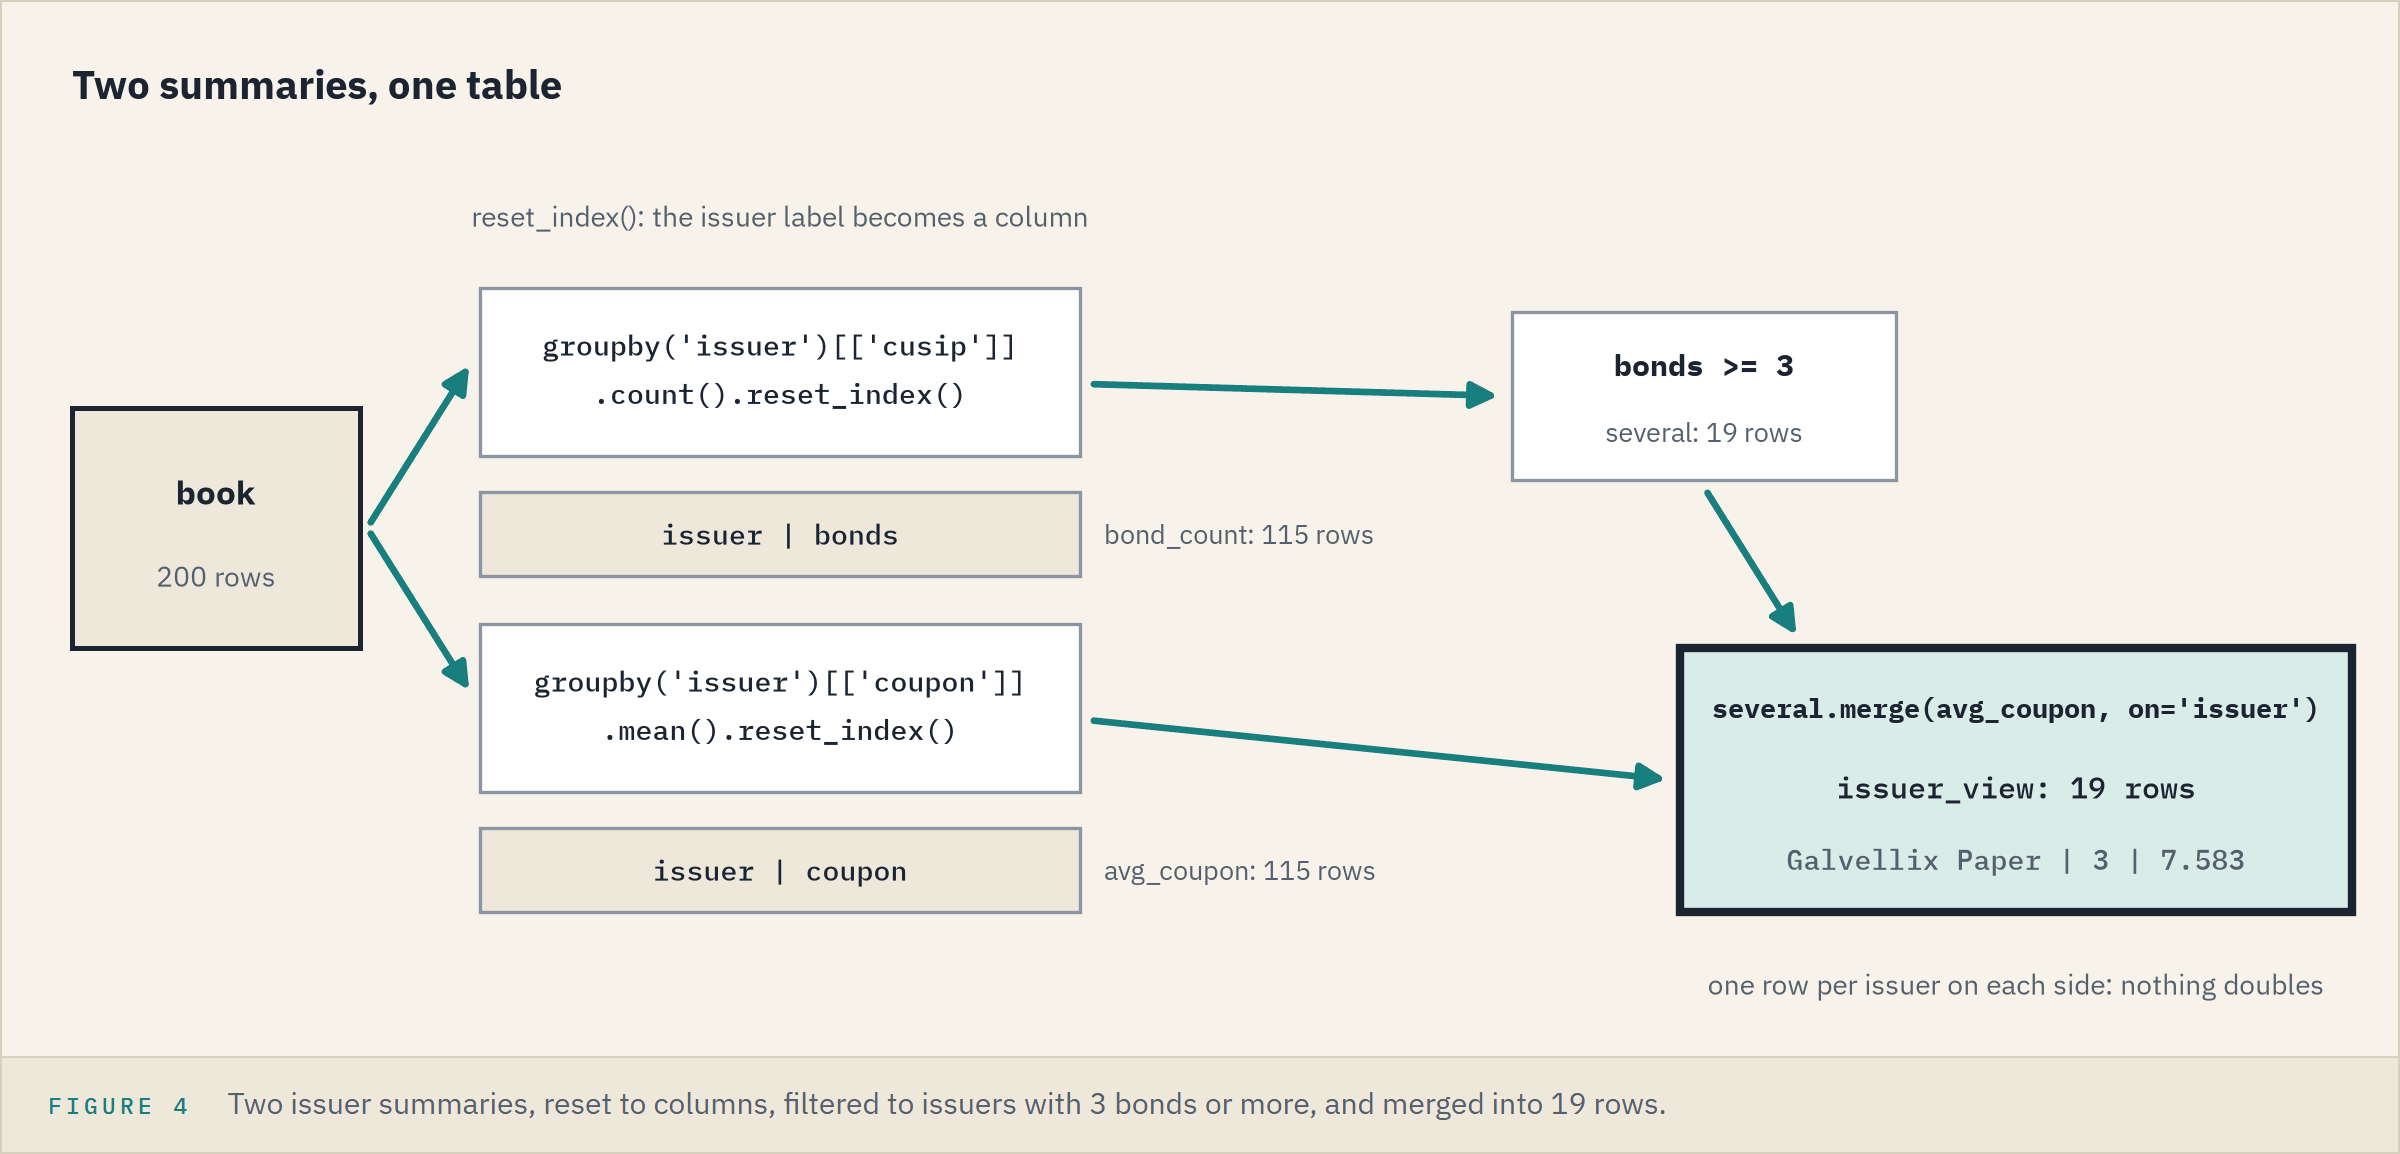

Each table has one row per issuer, so the merge cannot double a row.

**Excel side by side.** One PivotTable, issuer in Rows: Count of cusip and Average of coupon in Values, then the Row Labels arrow, Value Filters, Greater Than Or Equal To, 3 on the count.
With Sum of value in Values instead, Value Filters, Top 10 gives the ten largest issuers.

### Yesterday's Seven, Named

Q. Yesterday seven bonds were below par, maturing after 2040, and under 1,000,000 of face. Who are they?

In [30]:
# yesterday's three tests, now on the book
below = book['price'] < 100
long_dated = book['maturity'] > pd.Timestamp('2040-12-31')
small = book['par_held'] < 1000000
book.loc[below & long_dated & small, ['ticker', 'issuer', 'sector', 'rating', 'grade']]

,ticker,issuer,sector,rating,grade
3,BEZL,Bezoquil Freight,Transportation,BB,High Yield
18,CLDB,Calderby Retail,Consumer,B,High Yield
69,GALR,Galventor Power,Utilities,AA+,Investment Grade
86,HULR,Hulvimer Pipeline,Energy,BBB,Investment Grade
137,QVNE,Quorvane Energy,Energy,BBB,Investment Grade
174,VRAR,Vraxentor Retail,Consumer,BBB+,Investment Grade
184,WYXA,Wyxundra Energy,Energy,B+,High Yield


Four investment grade, three high yield.
CLDB is Calderby Retail, Consumer, rated B; its other bond is yesterday's 62.045.
The files say who; they never say why.

**The join puts a name on every number.**

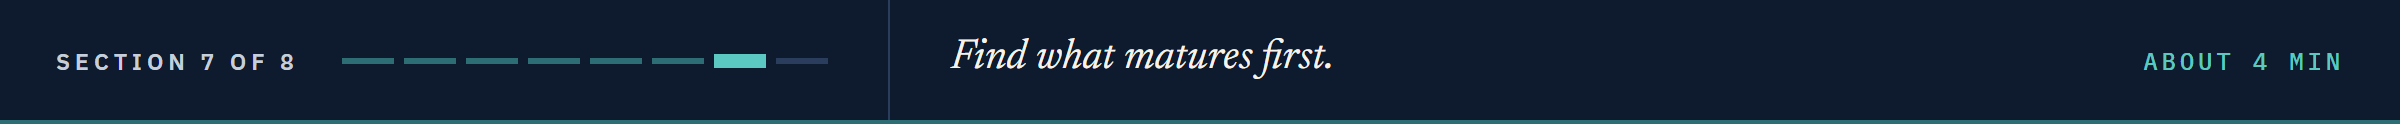

## 10.7 Maturity

### Two Labels

**Predict 5**

Q. `groupby()` also takes a list of two columns. How many rows does `book.groupby(['grade', 'maturity_bucket'], observed=True)['value'].sum()` return? Write down a number.

In [31]:
# one row for each pair of labels: grade first, then bucket
by_two = book.groupby(['grade', 'maturity_bucket'], observed=True)['value'].sum()
by_two

grade             maturity_bucket
High Yield        0 to 3              26639585.0
                  3 to 7              48891975.0
                  7 to 15             71265320.0
                  15 and over         19601222.5
Investment Grade  0 to 3              47232260.0
                  3 to 7              72423090.0
                  7 to 15            153886430.0
                  15 and over         43084347.5
Name: value, dtype: float64

8: two grades times four buckets, each row labelled by a pair.

### The Grid

Q. Lay it out as a grid, and draw it.

In [32]:
# unstack() lifts the grade from the row labels into the columns
grid = by_two.unstack('grade') / 1000000
grid.round(1)

grade,High Yield,Investment Grade
maturity_bucket,,
0 to 3,26.6,47.2
3 to 7,48.9,72.4
7 to 15,71.3,153.9
15 and over,19.6,43.1


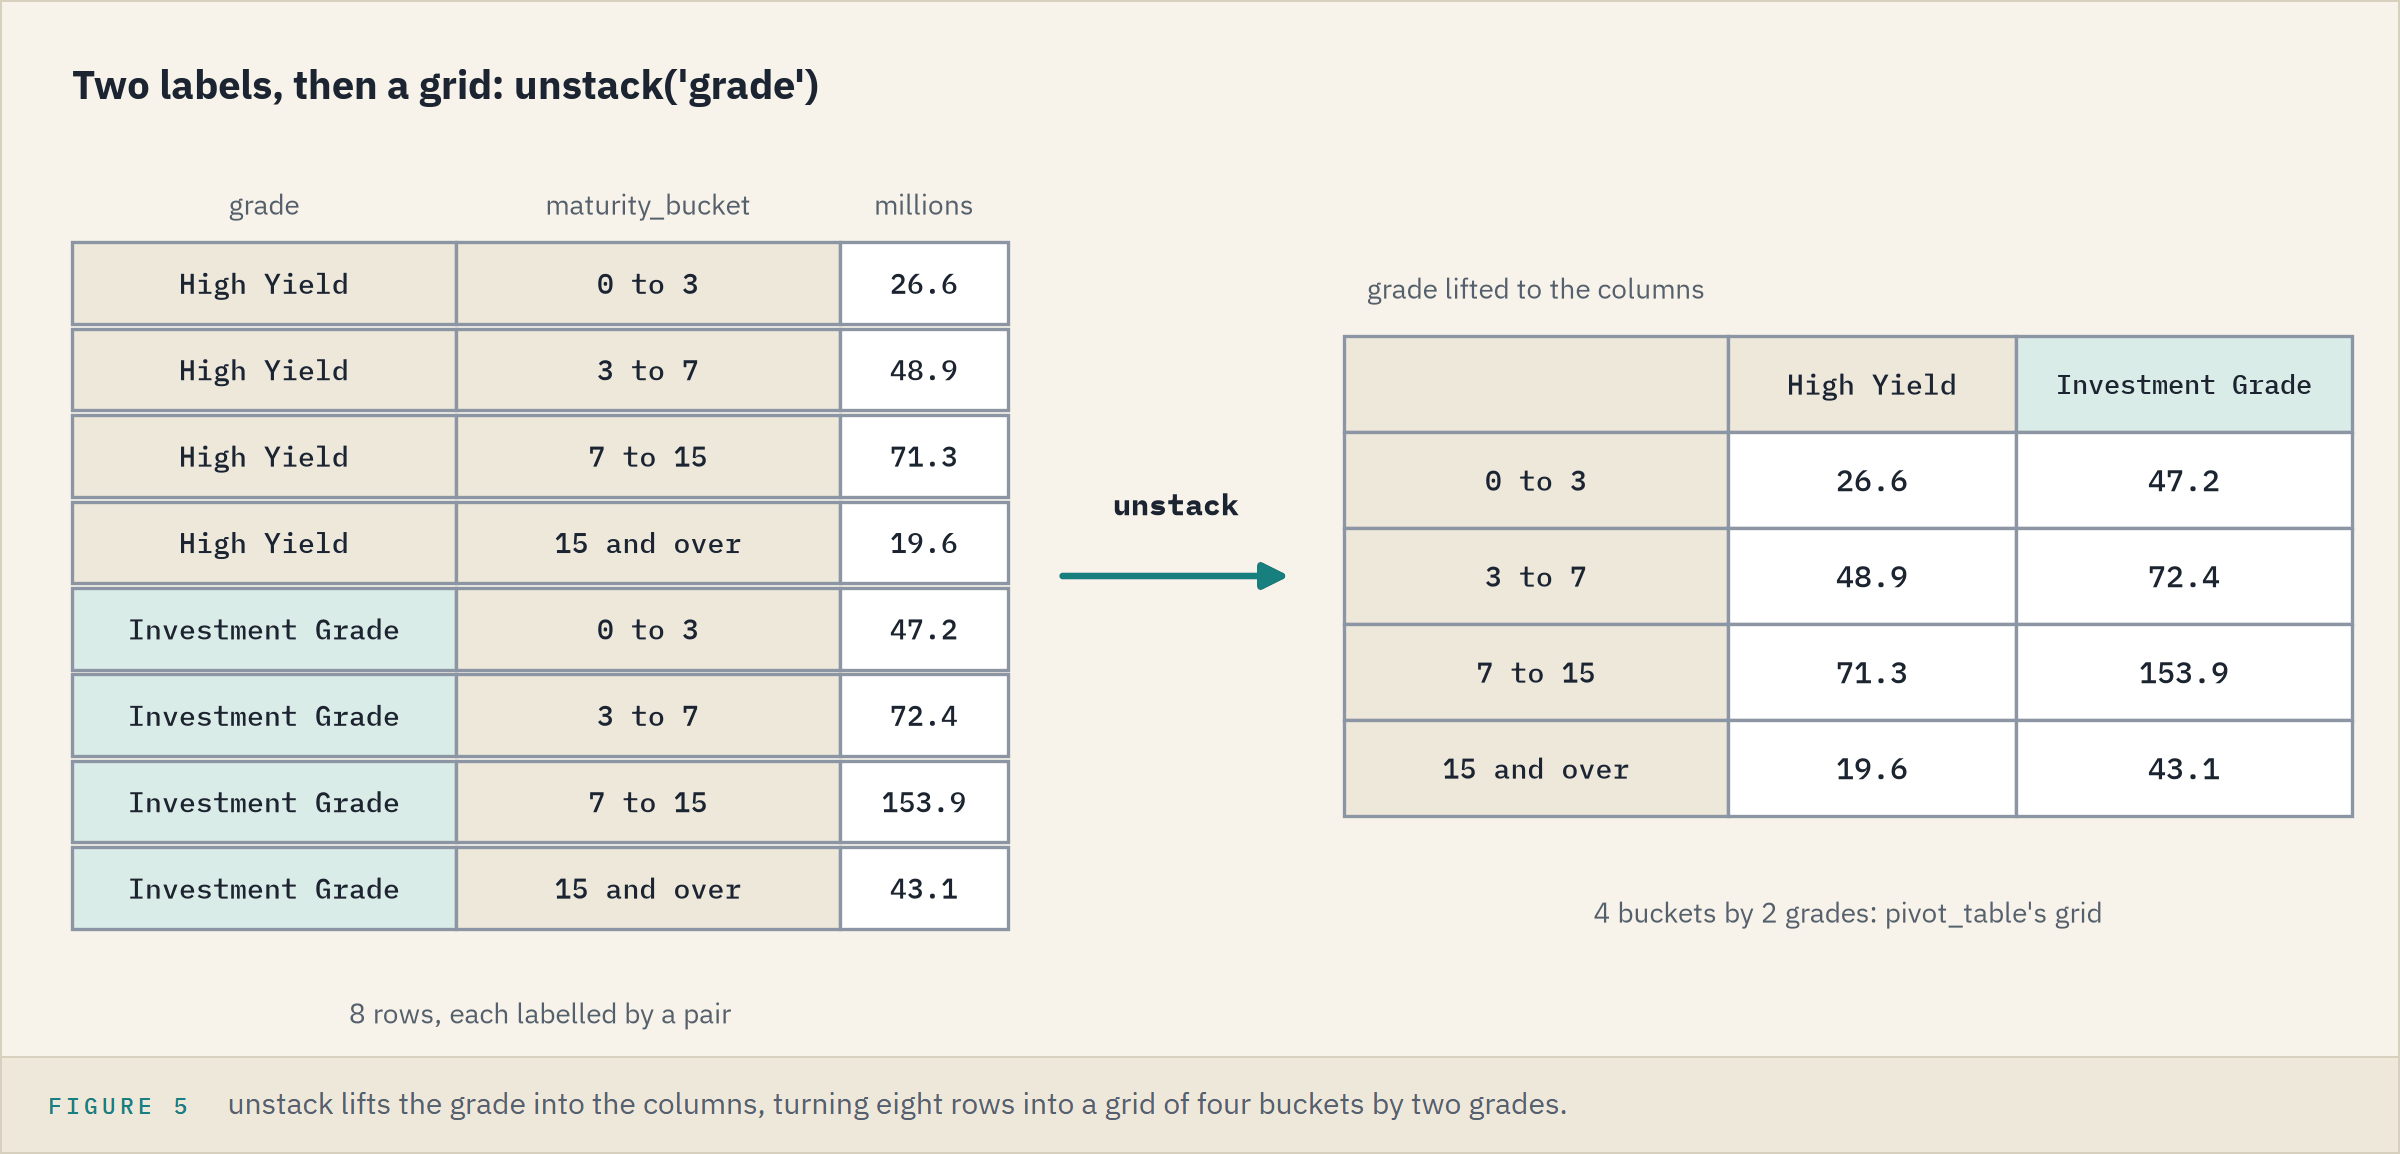

The same grid Combining Part 2's `pivot_table` builds.

**Excel side by side.** A PivotTable with grade and bucket both in Rows, then grade dragged from Rows to Columns.

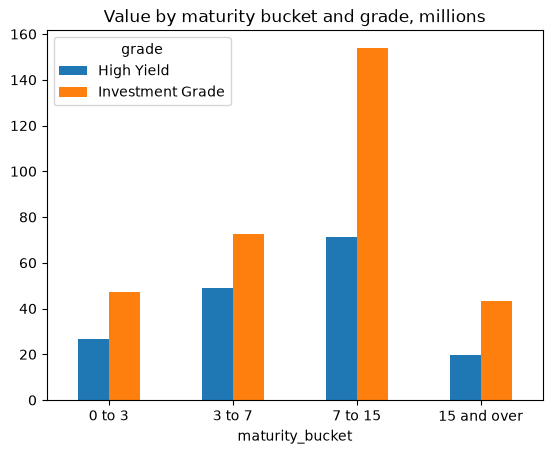

In [33]:
chart = grid.plot.bar(rot=0, title='Value by maturity bucket and grade, millions')

7 to 15 years is the tallest pair: 71.3 and 153.9 million, nearly half the book.

### Inside Three Years

Q. How much matures within three years, and which bonds come first?

In [34]:
# three years on from the report date; weight_pct adds straight to a share
within_three = book['maturity'] <= pd.Timestamp('2029-09-30')
print(within_three.sum(), book.loc[within_three, 'par_held'].sum())
print(round(book.loc[within_three, 'weight_pct'].sum(), 2))
print(book.loc[within_three, 'grade'].value_counts())

28 74000000
15.29
grade
Investment Grade    17
High Yield          11
Name: count, dtype: int64


In [35]:
# soonest first, with the issuer and grade the join brought in
maturing = book[within_three].sort_values('maturity')
maturing[['ticker', 'issuer', 'maturity', 'rating', 'grade']].head(5)

,ticker,issuer,maturity,rating,grade
177,VYRH,Veyrholt Health,2027-10-02,BB,High Yield
112,NEVR,Nevovar Energy,2027-10-24,BBB-,Investment Grade
70,GALX,Galvellix Paper,2027-10-27,B-,High Yield
125,PLWK,Pellwick Paper,2027-10-28,A-,Investment Grade
56,FARX,Farvellix Paper,2027-12-22,BB+,High Yield


17 of the 28 are investment grade and 11 high yield; Veyrholt Health's bond is first, on 2027-10-02.

**28 bonds, 15.29 percent of the book, mature first.**

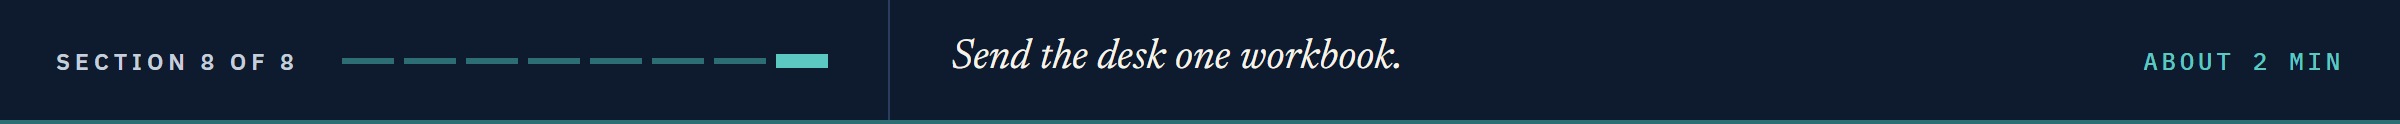

## 10.8 The Report

### One Workbook

Q. Write the book and the answers to one workbook, a sheet each.

In [36]:
# Combining Part 2's ExcelWriter: one workbook, one sheet per table
with pd.ExcelWriter('desk_book.xlsx') as writer:
    book.to_excel(writer, sheet_name='book', index=False)
    by_sector.to_excel(writer, sheet_name='sectors')
    by_grade.to_excel(writer, sheet_name='grades')
    by_bucket.to_excel(writer, sheet_name='buckets')
    top_ten.to_excel(writer, sheet_name='top_ten')

### Read It Back, Then Tidy

Q. Read every sheet back, check the book against its numbers, and remove the file.

In [37]:
# every sheet into a dictionary, as in Combining Part 2, the CUSIP kept as text
sheets = pd.read_excel('desk_book.xlsx', sheet_name=None, dtype={'cusip': str})
for name, table in sheets.items():
    print(name, table.shape)

book (200, 18)
sectors (10, 4)
grades (2, 3)
buckets (7, 5)
top_ten (10, 2)


In [38]:
back = sheets['book']
assert back['par_held'].sum() == face_before, 'the face changed in the file'
assert np.isclose(back['value'].sum(), total_value), 'the value changed in the file'
# done: nothing left behind
os.remove('desk_book.xlsx')
print(os.path.exists('desk_book.xlsx'))

False


**The note is answered in one file; next month the same cells run again.**

## Summary

The checks behind every answer:

<table align="left">
<tr><th align="left">Check</th><th align="left">Result</th></tr>
<tr><td align="left">Rows and face after each join</td><td align="left">200 and 489,000,000, twice</td></tr>
<tr><td align="left">Gaps in the columns brought in</td><td align="left">none</td></tr>
<tr><td align="left">The outer join</td><td align="left">489,000,000 of face, but 235 rows: stopped</td></tr>
<tr><td align="left">Weights</td><td align="left">add to 100, by <code>np.isclose()</code></td></tr>
<tr><td align="left">Sectors</td><td align="left">add back to 200 bonds and 483,024,230</td></tr>
<tr><td align="left">The workbook</td><td align="left">read back with the same face and value</td></tr>
</table>
<br clear="left">

## You Can Now

By the end of this notebook, you can:

* Join three tables into one book, checked for rows and for face after every join.
* Value a book at the clean price, with weights that add to 100.
* Answer a desk question in one `groupby`, and say what each share was divided by.
* Order ratings by their score, and average them through it.
* Group by two columns, `unstack()` the result, and merge two summaries.
* Draw bars across with `plot.barh()`, stacked or not.

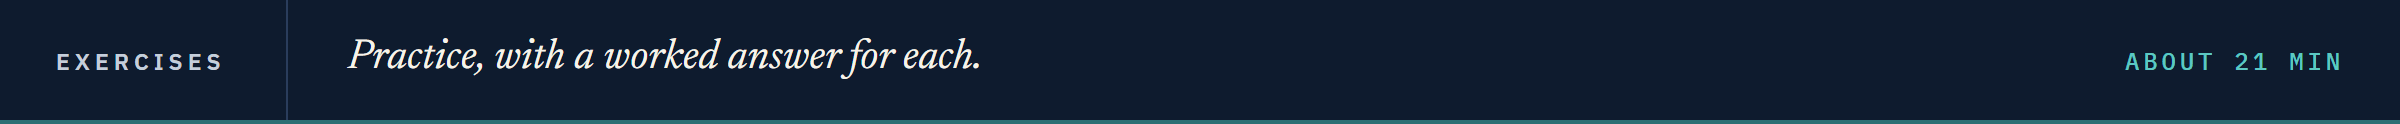

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

The desk's follow-up questions, each answered from the book; the issuers are invented.
Replace each `...` with your own code, then run the check cell under it.
Run the next two cells first: one defines `check`, which marks your answers; one rebuilds `book` with `value` and `coupon_income`.

In [39]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [40]:
import os

import pandas as pd

# fresh copies of the four files. In Colab they are read from GitHub.
if os.path.exists('../../../data/positions.csv'):
    data_folder = '../../../data/'
else:
    data_folder = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/'
positions = pd.read_csv(data_folder + 'positions.csv')
issuers = pd.read_csv(data_folder + 'issuers.csv')
ratings = pd.read_csv(data_folder + 'ratings.csv')
benchmark = pd.read_csv(data_folder + 'benchmark.csv')

# the book, rebuilt: two guarded left joins and two new columns
book = pd.merge(positions, issuers, on='ticker', how='left', validate='many_to_one')
book = pd.merge(book, ratings, on='rating', how='left', validate='many_to_one')
book['value'] = book['par_held'] * book['price'] / 100
book['coupon_income'] = book['par_held'] * book['coupon'] / 100
print(book.shape, book['par_held'].sum())

(200, 15) 489000000


### Exercise 1

Q. How many bonds, and how much face, does the book hold in Utilities and Transportation together? Use `isin()`; store the answers in **ex1_bonds** and **ex1_face**.

In [41]:
ex1_bonds = ...
ex1_face = ...

In [42]:
check('Exercise 1 bonds', ex1_bonds, 32)
check('Exercise 1 face', ex1_face, 79250000)

Exercise 1 bonds: not attempted yet
Exercise 1 face: not attempted yet


### Exercise 2

Q. What is the book's average price, simple and weighted by value? Round each to 2 decimal places and store them in **ex2_simple** and **ex2_weighted**. Is the weighted one higher? Store True or False in **ex2_weighted_higher**.

In [43]:
ex2_simple = ...
ex2_weighted = ...
ex2_weighted_higher = ...

In [44]:
check('Exercise 2 simple', ex2_simple, 98.83)
check('Exercise 2 weighted', ex2_weighted, 99.33)
check('Exercise 2 weighted higher', ex2_weighted_higher, True)

Exercise 2 simple: not attempted yet
Exercise 2 weighted: not attempted yet
Exercise 2 weighted higher: not attempted yet


### Exercise 3

Q. Which three sectors pay the most coupon income a year, largest first? Store their names as a list in **ex3_top_three**, and the largest one's income in **ex3_top_income**.

In [45]:
ex3_top_three = ...
ex3_top_income = ...

In [46]:
check('Exercise 3 top three', ex3_top_three, ['Materials', 'Financials', 'Consumer'])
check('Exercise 3 top income', ex3_top_income, 4205937.5)

Exercise 3 top three: not attempted yet
Exercise 3 top income: not attempted yet


### Exercise 4

The benchmark's `accrued` column is accrued interest per 100 of face, one row per `cusip`.

Q. Left-join the book with the benchmark's `cusip` and `accrued` columns. Store the rows in **ex4_rows**, the book's accrued interest in **ex4_accrued**, and its value with accrued in **ex4_full_value**, the last two rounded to 2 decimal places.

In [47]:
ex4_rows = ...
ex4_accrued = ...
ex4_full_value = ...

In [48]:
check('Exercise 4 rows', ex4_rows, 200)
check('Exercise 4 accrued', ex4_accrued, 7794985.0)
check('Exercise 4 full value', ex4_full_value, 490819215.0)

Exercise 4 rows: not attempted yet
Exercise 4 accrued: not attempted yet
Exercise 4 full value: not attempted yet


### Exercise 5

Q. Write `join_is_safe(before, after)`, returning True when the two tables have the same number of rows and the same total `par_held`, and False otherwise; replace `return ...` with your code. Then call it on the positions and their outer join with the issuers on `ticker`, and store what it returns in **ex5_outer_safe**.

In [49]:
def join_is_safe(before, after):
    """
    Take the table before a join and the table after it,
    and return True when both have the same number of rows
    and the same total par_held. Return False otherwise.
    """
    return ...

ex5_outer_safe = ...

In [50]:
# the first check calls your function on the positions and the book
check('Exercise 5 left joins', join_is_safe(positions, book), True)
check('Exercise 5 outer join', ex5_outer_safe, False)

Exercise 5 left joins: not attempted yet
Exercise 5 outer join: not attempted yet


### Exercise 6

Q. Build the lesson's two issuer summaries, keep the issuers with four bonds or more, and merge the two. How many are left, which has the highest average coupon, and what is it, to 3 decimal places? Store the answers in **ex6_count**, **ex6_top_issuer**, and **ex6_top_coupon**.

In [51]:
ex6_count = ...
ex6_top_issuer = ...
ex6_top_coupon = ...

In [52]:
check('Exercise 6 count', ex6_count, 4)
check('Exercise 6 top issuer', ex6_top_issuer, 'Nevulex Health')
check('Exercise 6 top coupon', ex6_top_coupon, 5.396)

Exercise 6 count: not attempted yet
Exercise 6 top issuer: not attempted yet
Exercise 6 top coupon: not attempted yet


### Exercise 7: AI check

You ask an AI assistant how many bonds the desk holds in Utilities and Transportation.
The code below was written for this course in the style of an AI answer, and it has one bug.

Q. What number do you expect, from Exercise 1? Run the code. Does it agree?

In [53]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
# join the issuers, the positions, and the rating scale into one table
joined = pd.merge(issuers, positions, on='ticker', how='left')
joined = pd.merge(joined, ratings, on='rating', how='left')

# the rows in the two sectors
two_sectors = joined[joined['sector'].isin(['Utilities', 'Transportation'])]
ex7_bonds = len(two_sectors)

print(f'Bonds in Utilities and Transportation: {ex7_bonds}')

Bonds in Utilities and Transportation: 47


Q. Find the bug and fix the code above, so that **ex7_bonds** holds the right answer.

In [54]:
check('Exercise 7 bonds', ex7_bonds, 32)

Exercise 7 bonds: not yet. You have 47


## Congratulations!

The note is answered:

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Answer</th></tr>
<tr><td align="left">One book</td><td align="left">200 rows, 13 columns, 489,000,000 of face</td></tr>
<tr><td align="left">Value, income, weight</td><td align="left">483,024,230; 28,864,375 a year; weights add to 100</td></tr>
<tr><td align="left">By sector</td><td align="left">Materials first, 14.60 percent</td></tr>
<tr><td align="left">By grade</td><td align="left">investment grade 64.0 percent by count, 65.55 by value</td></tr>
<tr><td align="left">By rating</td><td align="left">BBB 30.82 percent, A 30.38</td></tr>
<tr><td align="left">Average rating</td><td align="left">score 9.25, between BBB and BBB-</td></tr>
<tr><td align="left">Ten largest issuers</td><td align="left">20.67 percent, Elverone Industrial first</td></tr>
<tr><td align="left">Maturing first</td><td align="left">28 bonds, 15.29 percent, from 2027-10-02</td></tr>
<tr><td align="left">Yesterday's seven</td><td align="left">four investment grade, three high yield</td></tr>
<tr><td align="left">One workbook</td><td align="left">five sheets, read back, removed</td></tr>
</table>
<br clear="left">

Be proud: you ran week 2's whole toolkit, loading, checking, joining, summarizing, and saving, as one job the desk can rerun next month.

Next week opens with Visualization: the same book, drawn chart by chart with every part labelled.

[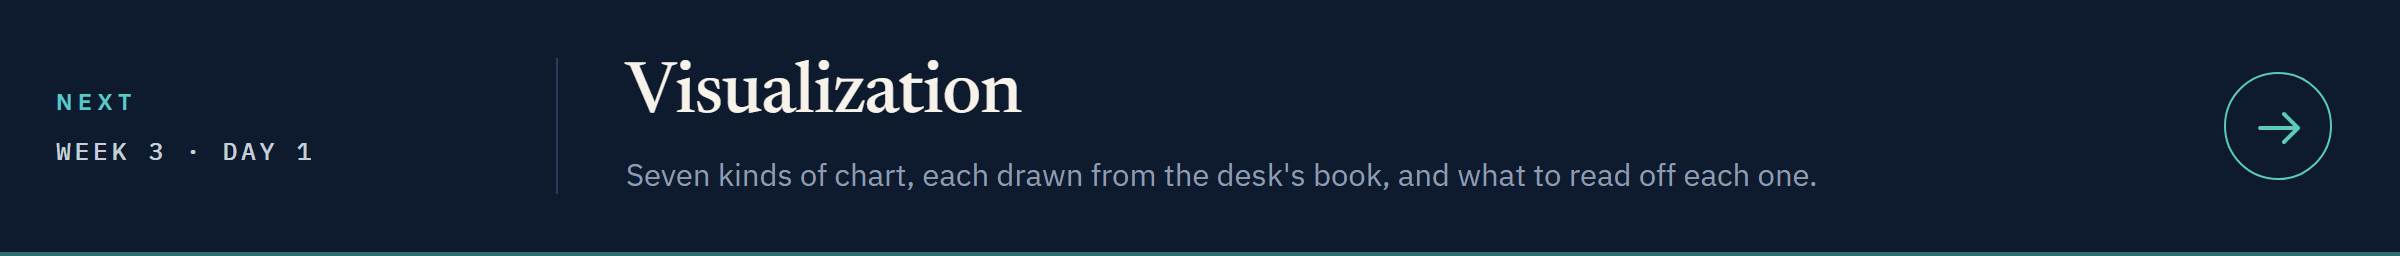](../../week3/day1/11_visualization.ipynb)

[Open Day 1 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week3/day1/11_visualization.ipynb)